<a href="https://colab.research.google.com/github/oussamalembarki/concepts-ml-et-tp/blob/main/demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

K-means++ : [475, 430, 1295]
DBSCAN    : [5, 1973, 200, 18, 4]


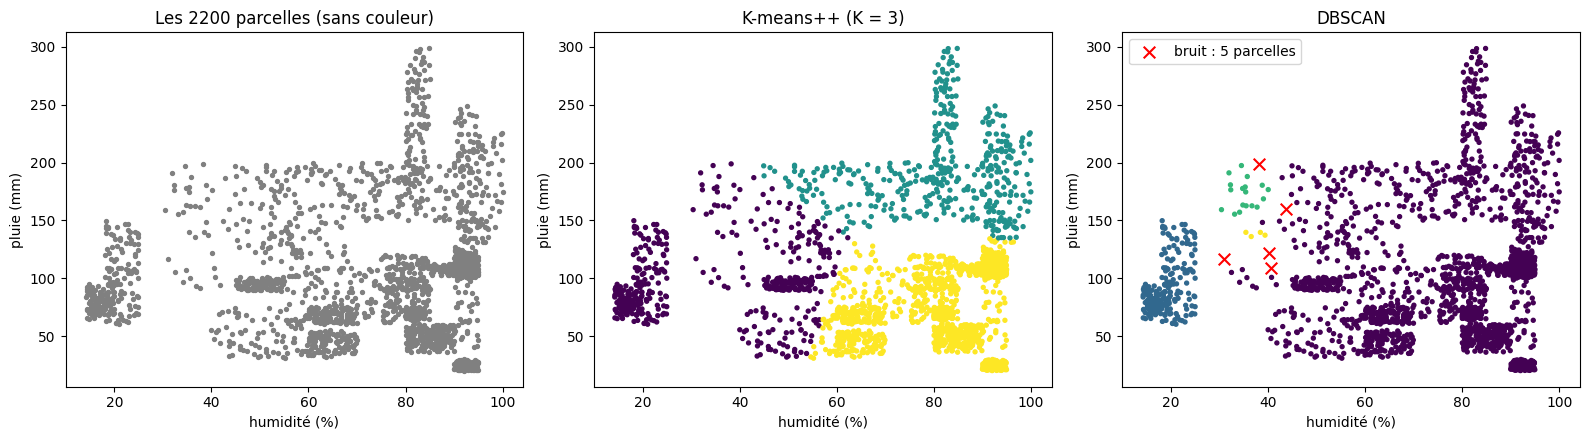

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN

df = pd.read_csv('Crop_recommendation.csv')

# 1. On garde 2 variables pour pouvoir dessiner : humidité et pluie
cols = ['humidity', 'rainfall']

# 2. On standardise (mise à l'échelle, vue en cours)
X = StandardScaler().fit_transform(df[cols])

# 3. On applique les deux algorithmes
km = KMeans(n_clusters=3, init='k-means++', n_init=10, random_state=0).fit(X)
db = DBSCAN(eps=0.2, min_samples=5).fit(X)
bruit = (db.labels_ == -1)

# 4. On dessine : les parcelles, puis le résultat de chaque algorithme
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

ax[0].scatter(df['humidity'], df['rainfall'], s=8, color='gray')
ax[0].set_title("Les 2200 parcelles (sans couleur)")

ax[1].scatter(df['humidity'], df['rainfall'], c=km.labels_, cmap='viridis', s=8)
ax[1].set_title("K-means++ (K = 3)")

ax[2].scatter(df.loc[~bruit, 'humidity'], df.loc[~bruit, 'rainfall'],
              c=db.labels_[~bruit], cmap='viridis', s=8)
ax[2].scatter(df.loc[bruit, 'humidity'], df.loc[bruit, 'rainfall'],
              c='red', marker='x', s=70, label=f"bruit : {bruit.sum()} parcelles")
ax[2].set_title("DBSCAN")
ax[2].legend()

for a in ax:
    a.set_xlabel("humidité (%)")
    a.set_ylabel("pluie (mm)")
plt.tight_layout()

# 5. Taille de chaque groupe (pour DBSCAN, le premier chiffre = le bruit)
print("K-means++ :", pd.Series(km.labels_).value_counts().sort_index().tolist())
print("DBSCAN    :", pd.Series(db.labels_).value_counts().sort_index().tolist())

plt.show()